# Lab 13: How to give an agent a search tool

## Goal

Give the agent search as a tool, so it can search again for what a file it has just read points to. The moment is a
rep's question: *"Ticket 06's replacement arrived warped too. What do we offer now, and how long does the refund
take?"* The ticket says only that the damaged-media policy replaces a copy once; the rule for a second time is in a
policy file the question never names. One search that returns the 2 or the 4 nearest files misses that rule. Given
the search as a tool, the agent reads ticket 06, writes its own second query for the damaged-media policy, and
answers both parts. We then measure what the agent costs, and when a single search with more results is enough.

## What you will learn

- How to turn retrieval into a tool whose query the model writes, and print every query it writes.
- How to step through the agent's turns by hand before packaging them in `run_loop` with a turn cap.
- How to tell a planned split (every query written from the question) from a dependent hop (a query written from a
  file the agent has just read).
- How to compare single-shot retrieval at k = 2, 4 and 6 with the agent in correct facts, model calls, tokens and
  cost, and say when a bigger k is enough.
- How the agent stops on a question the files cannot answer, and what the turn cap is for.

## Where this lab starts

Two ideas from earlier labs meet here. Lab 12 built **single-shot RAG**: embed every file, store the vectors in
Chroma, embed the question, take the k nearest files and pack them into the prompt with a rule to answer only from
them. One retrieve, one generate. Lab 03 wrote the **agent loop**: send the messages with the tools, run every tool
the model asks for, append the results, and repeat until the model writes text or a turn cap stops it.

This lab gives the loop one tool: the search from lab 12. The notebook restates everything it uses, so it runs on its
own.

| | Single-shot RAG (lab 12) | Agentic RAG (this lab) |
|---|---|---|
| Corpus | The same 36 files | The same 36 files |
| Store | Chroma, in memory | Chroma, in memory |
| The embedding call | Same shape | Same shape |
| How many times we search | Exactly once, every time | The model decides: once, several times, or it gives up |
| Who writes the search query | Nobody: the user's question is the query | The model, one short query per search |

### The question and what a right answer needs

The rep's question asks for two facts:

1. *What do we offer now that the replacement is damaged too?* A refund instead of a third copy. This is in
   `policy_damaged_media.md`: "If the same title arrives damaged twice, offer a refund instead of a third copy."
2. *How long does the refund take?* 5 to 10 business days after support approves it. This is in
   `policy_refunds.md`.

The question names neither file. It names ticket 06 (`ticket_06_germany_warped_vinyl.md`), and the ticket says
"Damaged-media policy: replace once at no charge". So the way to fact 1 goes through the ticket: read the ticket, then
search for the policy it names. A search whose query depends on what an earlier result said is a **dependent hop**.

Here retrieval becomes a **tool**. The model inspects what it retrieved, determines what facts are still missing, and
decides whether to search again or stop. That is agentic RAG. The store did not change. Chroma is still Chroma.

The picture below is the loop we will build. The black boxes are the model's work; the lime boxes are our code's.

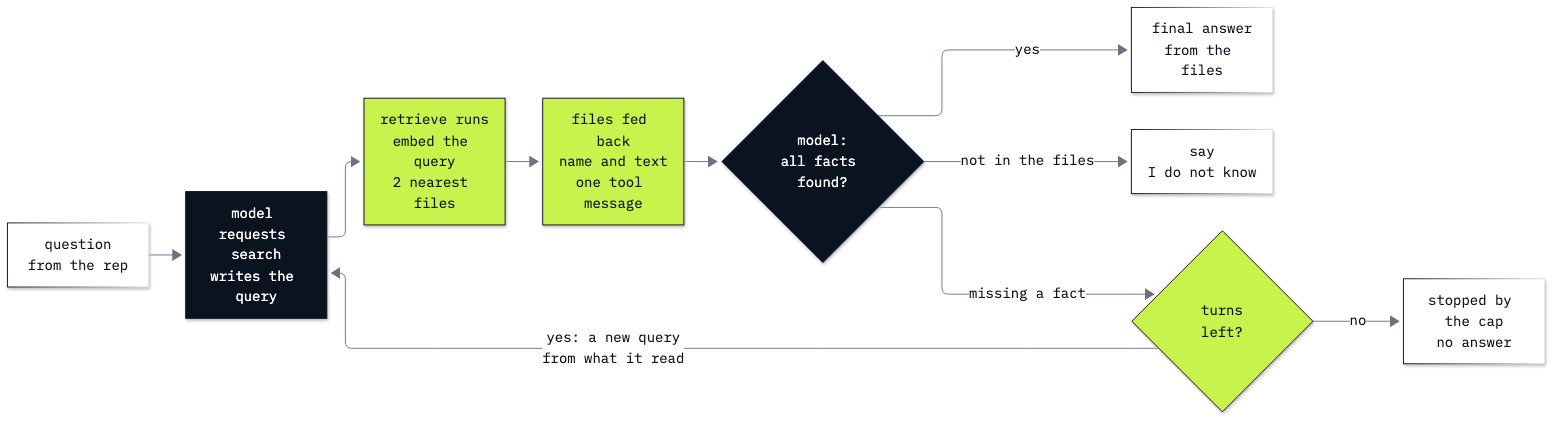

In [1]:
from IPython.display import Image

Image("resources/lab13_agentic_rag.png", width=760)

Read it from the question: the model asks for a search and writes the query; our code runs the search and feeds the
files back; the model then decides whether all the facts are there. A missing fact sends it round again, with a new
query it writes from what it has read. Two of its exits are answers (the facts, or "the files do not say"); the third
exit, the turn cap, is ours.

---

## Setup

The config cell is the same in every lab: it finds the repository folder by `models.env`, reads the models and the
prices from there, and finds your key without printing it (Lab 00 reads it line by line).

In [2]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


Next, the client and the settings every call shares. `EMBED_MODEL` is the embedding model named in `models.env`; it
turns a text into a vector, as in lab 12. `MAX_OUTPUT` caps each model reply at 200 tokens, far more than a tool call
or a two-sentence answer needs. The prices (US dollars per million tokens) let Part F say what each approach cost.

In [3]:
from openai import OpenAI, omit

client = OpenAI()
EMBED_MODEL = settings["EMBEDDING_MODEL"]
MAX_OUTPUT = 200
PRICE_IN = float(settings["PRICE_INPUT_PER_MILLION"])
PRICE_OUT = float(settings["PRICE_OUTPUT_PER_MILLION"])
print("embedding model:", EMBED_MODEL)
print("input:", PRICE_IN, "| output:", PRICE_OUT, "US dollars per million tokens")

embedding model: text-embedding-3-small
input: 0.1 | output: 0.5 US dollars per million tokens


Every model call below passes `reasoning_effort=EFFORT or omit`. `omit` is the OpenAI library's marker for "leave this
argument out of the request": when `models.env` sets no effort (a model without a reasoning setting), the request goes
without it instead of sending an empty value the API rejects. With `none`, as here, tools work on Chat Completions,
which this lab uses as the fundamental; the frameworks in later labs run the same loop on the newer Responses API.

---

## Part A: See why one search misses the second fact

Before we give the model a tool, we run the pipeline lab 12 built on our question, so we can see exactly what a single
search returns and where it falls short.

### Step 1: Index the 36 files in this kernel

The shop's documents are 36 short markdown files in `data/corpus/`: 20 policies and 16 support tickets. We read them
in place and never change them. First, the file the question is about:

In [4]:
CORPUS = ROOT / "data" / "corpus"
files = sorted(CORPUS.glob("*.md"))
print(len(files), "files")
print()
print((CORPUS / "ticket_06_germany_warped_vinyl.md").read_text())

36 files

# Ticket 06 — Germany, warped vinyl

Date: 2012-07-18
Customer: billing country Germany

Vinyl arrived warped. Customer sent a photo. Damaged-media policy: replace once at no charge.

Status: resolved. Replacement shipped 2012-07-20.



Ticket 06 is a record of what happened: the vinyl arrived warped, and under the damaged-media policy the shop sent one
free replacement. Notice what it does not say. It names the policy ("Damaged-media policy: replace once at no
charge") but does not quote the policy's rule for a second damaged copy, and it says nothing about refunds. Both facts
our question needs live in other files.

Now we embed all 36 files. The embeddings endpoint takes a list in `input` and returns one vector per text in
`data`, **in the same order**, so `vectors[i]` belongs to `files[i]`. One request for 36 texts is cheaper and faster
than 36 requests.

In [5]:
texts = [path.read_text() for path in files]
response = client.embeddings.create(model=EMBED_MODEL, input=texts)
vectors = [item.embedding for item in response.data]
print(len(vectors), "vectors of", len(vectors[0]), "numbers each")
print("embedding tokens:", response.usage.total_tokens)

36 vectors of 1536 numbers each
embedding tokens: 2551


36 vectors, one per file, each a list of 1,536 numbers (the embedding model's fixed size), in the same order as `files`. The whole corpus is 2,551 tokens, so embedding all of it costs a small fraction of a cent.

We store them in Chroma, the vector store lab 12 used. `chromadb.Client()` runs inside this Python process and keeps
everything in memory, so nothing is written to disk and nothing needs a server. The ids are the file names, so every
search result says which file it came from. `upsert` adds each id, or replaces it if the id is already there, so the
cell is safe to run twice.

In [6]:
import chromadb

chroma = chromadb.Client()
collection = chroma.get_or_create_collection("corpus")
collection.upsert(ids=[path.name for path in files], documents=texts, embeddings=vectors)
print("stored:", collection.count())

stored: 36


### Step 2: `retrieve` is an ordinary function

A search embeds the query with the same model and asks Chroma for the nearest stored vectors. Here is the raw call on
our question, before we wrap it in a function:

In [7]:
import json


def embed(text):
    return client.embeddings.create(model=EMBED_MODEL, input=text).data[0].embedding


QUESTION = "Ticket 06's replacement arrived warped too. What do we offer now, and how long does the refund take?"

got = collection.query(query_embeddings=[embed(QUESTION)], n_results=2)
print(list(got.keys()))
print(got["ids"])
print(got["distances"])

['ids', 'embeddings', 'documents', 'uris', 'included', 'data', 'metadatas', 'distances']
[['ticket_06_germany_warped_vinyl.md', 'ticket_01_helena_wrong_album.md']]
[[0.7950804233551025, 1.0113286972045898]]


`collection.query` returns a dictionary. Every field is a **list of lists**: one inner list per query vector we sent.
We sent one, so `got["ids"][0]` is our answer: the two nearest files, `ticket_06_germany_warped_vinyl.md` and `ticket_01_helena_wrong_album.md`, and in `got["distances"][0]` their distances, 0.7951 and 1.0113 (printed with all their decimals). The `distance` is the squared distance between the
question's vector and the file's vector: smaller means closer (lab 12 shows it gives the same order as cosine
similarity).

`retrieve` does the same call for any query and any `k`, and turns the lists into one small dictionary per file:
its id, its distance and its text. Below it, we ask for the six nearest files and number them from 1 with
`enumerate(..., start=1)`.

In [8]:
def retrieve(query, k):
    got = collection.query(query_embeddings=[embed(query)], n_results=k)
    rows = []
    for i in range(len(got["ids"][0])):
        rows.append({
            "id": got["ids"][0][i],
            "distance": got["distances"][0][i],
            "document": got["documents"][0][i],
        })
    return rows


for rank, row in enumerate(retrieve(QUESTION, 6), start=1):
    print(f"{rank}. {row['distance']:.4f}  {row['id']}")

1. 0.7951  ticket_06_germany_warped_vinyl.md
2. 1.0113  ticket_01_helena_wrong_album.md
3. 1.0356  policy_refunds.md
4. 1.0364  ticket_07_uk_preorder_delay.md
5. 1.0945  policy_damaged_media.md
6. 1.1036  ticket_11_ireland_exchange.md


These are the six files nearest to the question, best first. A search with `k=2` returns the first two rows, `k=4`
the first four, and so on. Reading them against the two facts:

- **1st, ticket 06** (0.7951): the question names it, so it is by far the nearest.
- **2nd, ticket 01** (1.0113): Helena's wrong album, a different case. It shares the words "replacement" and "refund" with the question.
- **3rd, `policy_refunds.md`** (1.0356): fact 2, the refund time.
- **4th, ticket 07** (1.0364): a cancelled preorder whose refund took 8 business days, one customer's case, not the policy.
- **5th, `policy_damaged_media.md`** (1.0945): fact 1, the second-time rule. The question says "warped" and "replacement"; the rule says "the same title arrives damaged twice" and "a third copy".

So `k=2` gets neither policy, and `k=4` gets the refund policy but not the damaged-media policy.

### Step 3: Single-shot RAG at `k=2` and `k=4`: the failure case

`generate` is lab 12's generate step: pack the files into the prompt and answer only from them, or say so. It returns
the reply and the call's `usage` (the tokens sent and received), which Part F prices.

We also write down, as code, what a right answer contains, so every run in this lab is checked the same way.
`check_facts` looks for fact 1 (a refund offered *instead of* or *rather than* another copy) and fact 2 ("5 to 10
business days", with "to" or a dash).

In [9]:
import re

GENERATE_RULES = (
    "Answer using only the documents. "
    "If they do not contain the answer, say you do not know. "
    "Do not invent a number, a date, or a phone number."
)


def generate(question, rows):
    packed = "\n\n".join(f"# {row['id']}\n{row['document']}" for row in rows)
    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "system", "content": GENERATE_RULES},
            {"role": "user", "content": "Documents:\n\n" + packed + "\n\nQuestion: " + question},
        ],
        max_completion_tokens=MAX_OUTPUT,
        reasoning_effort=EFFORT or omit,
    )
    return response.choices[0].message.content, response.usage


def check_facts(text):
    text = (text or "").lower()
    rule = "refund" in text and any(phrase in text for phrase in ["third", "instead of", "rather than"])
    days = re.search(r"5\s*(to|-|–)\s*10 business days", text) is not None
    return {"refund instead of a third copy": rule, "5 to 10 business days": days}


print(check_facts("Offer a refund instead of a third copy. It takes 5 to 10 business days."))
print(check_facts("The documents do not say. I do not know."))

{'refund instead of a third copy': True, '5 to 10 business days': True}
{'refund instead of a third copy': False, '5 to 10 business days': False}


The check passes a hand-written right answer on both facts and fails "I do not know" on both. It is a keyword check:
it would also pass a reply that said "do **not** offer a refund instead of a third copy", so we read every reply it
scores, not only the ✅.

Now single-shot RAG on our question, three times at `k=2` and three times at `k=4`. The files are the same every time
(the search has no randomness); only the model's wording can change.

In [10]:
single_shot = {}
for k in (2, 4):
    rows = retrieve(QUESTION, k)
    print(f"k={k}: files", [row["id"] for row in rows])
    single_shot[k] = []
    for run in range(1, 4):
        text, usage = generate(QUESTION, rows)
        facts = check_facts(text)
        single_shot[k].append({"text": text, "usage": usage, "facts": facts})
        marks = " ".join(("✅" if ok else "❌") + " " + name for name, ok in facts.items())
        print(f"  run {run}: {marks} | prompt tokens {usage.prompt_tokens}")
        print("   ", text.replace("\n", " "))
    print()

k=2: files ['ticket_06_germany_warped_vinyl.md', 'ticket_01_helena_wrong_album.md']


  run 1: ❌ refund instead of a third copy ❌ 5 to 10 business days | prompt tokens 240
    The documents don’t say what to offer after the replacement is also warped, or how long a refund takes. The damaged-media policy only says to replace it once at no charge.


  run 2: ❌ refund instead of a third copy ❌ 5 to 10 business days | prompt tokens 240
    The documents don’t say what to offer after the replacement also arrives warped, or how long a refund takes. The damaged-media policy only says the first replacement is free.


  run 3: ❌ refund instead of a third copy ❌ 5 to 10 business days | prompt tokens 240
    The documents only cover a warped-vinyl replacement once at no charge, and say Ticket 06’s replacement shipped on 2012-07-20. They don’t say what to offer if that replacement is also warped or how long a refund takes, so I don’t know.



k=4: files ['ticket_06_germany_warped_vinyl.md', 'ticket_01_helena_wrong_album.md', 'policy_refunds.md', 'ticket_07_uk_preorder_delay.md']


  run 1: ❌ refund instead of a third copy ✅ 5 to 10 business days | prompt tokens 426
    Ticket 06’s policy allows one free replacement, which has already been sent. The documents don’t say what to offer if that replacement is also warped, so I don’t know. If a refund is approved, it goes back to the original payment method and takes **5–10 business days**.


  run 2: ❌ refund instead of a third copy ✅ 5 to 10 business days | prompt tokens 426
    Ticket 06’s record can be replaced once at no charge, and that replacement has already been sent. The documents don’t say what to offer if the replacement is also warped, so I don’t know.  If a refund is approved, it goes back to the original payment method and takes 5–10 business days.


  run 3: ❌ refund instead of a third copy ✅ 5 to 10 business days | prompt tokens 426
    The damaged-media policy allows one free replacement, which has already been sent. The documents don’t say what to offer if that replacement also arrives warped, so I don’t know.  If a refund is approved, it takes **5 to 10 business days** to return to the original payment method.



At `k=2` all three replies miss both facts. The model had ticket 06 and ticket 01; neither says what to do the second time or how long a refund takes, and each reply says the documents do not say. At `k=4` all three give the refund time, 5 to 10 business days, from `policy_refunds.md`, and still say they do not know what to offer now. Every run at one `k` sends the same files, so the prompt tokens repeat: 240 at `k=2`, 426 at `k=4`.

Single-shot retrieval failed to answer the full question because it never saw the damaged-media policy. Notice also
what did **not** go wrong: the generate step did not invent a rule. Its instructions say to answer only from the
documents, and it kept to them. **The miss is in the search, not in the answer.**

Why not simply raise `k` until the policy is in? The policy is 5th, so `k=6` would reach it. Part F tries exactly
that and measures it against the agent. First we build the agent, because a person would not solve this by reading
more files at random: they would read ticket 06, see that it names the damaged-media policy, and look that up.

**Checkpoint A.** At `k=2`: ticket 06 and ticket 01, and a reply missing both facts. At `k=4`: the refund time
(5 to 10 business days) but not what to offer now. A pass shows the single search misses the second-time rule on
this question; it does not show that single-shot RAG is wrong in general (Part E has a question it answers).

---

## Part B: Give the model search as a tool

Now let's build agentic retrieval. The model gets the search as a tool, so it can write its own queries, one per
thing it needs, and search again after reading a result.

### Step 4: Define the `retrieve` tool and its schema

The model never sees our Python function, only a description of it: a JSON schema in Chat Completions' tool format,
as lab 02 wrote. There is one tool, so we write the dictionary out in full:

- `name`: what the model writes when it asks for the tool.
- `description`: what the model reads to decide when to call it and how to word the query.
- `parameters`: one required string, `query`.

In [11]:
TOOL_K = 2  # each search returns the 2 nearest files

TOOLS = [
    {
        "type": "function",
        "function": {
            "name": "retrieve",
            "description": (
                "Search the shop policy and customer ticket files. "
                "Argument query must be a concise keyword phrase "
                "(e.g. 'gift card expiry', 'student discount', 'Puja ticket'). "
                "Do not repeat keywords from files already retrieved."
            ),
            "parameters": {
                "type": "object",
                "properties": {"query": {"type": "string"}},
                "required": ["query"],
            },
        },
    }
]
print(json.dumps(TOOLS[0], indent=2))

{
  "type": "function",
  "function": {
    "name": "retrieve",
    "description": "Search the shop policy and customer ticket files. Argument query must be a concise keyword phrase (e.g. 'gift card expiry', 'student discount', 'Puja ticket'). Do not repeat keywords from files already retrieved.",
    "parameters": {
      "type": "object",
      "properties": {
        "query": {
          "type": "string"
        }
      },
      "required": [
        "query"
      ]
    }
  }
}


Two choices in this schema matter for the rest of the lab:

- **The examples in the description are about other topics on purpose** (gift cards, a student discount, Puja's
  ticket). An example close to a test question can hand the model its query, and then a good run tests the example,
  not the agent.
- **Each search returns 2 files** (`TOOL_K = 2`). A short query aims at one topic, so two results are usually enough,
  and they keep every turn's prompt short. To read more, the model must search again: that is the behaviour we want
  to see.

When the model asks for the tool, our code runs `run_retrieve(query)`: the search, then a tool result the model can
read, each file's name followed by its text. We leave the distance out; the model reads the text, and a number with no
scale is easy to misread. Here it is on a query about another topic, so you can see what the model will receive:

In [12]:
def run_retrieve(query):
    rows = retrieve(query, TOOL_K)
    names = [row["id"] for row in rows]
    content = "\n\n".join(f"{row['id']}\n{row['document']}" for row in rows)
    return names, content


names, content = run_retrieve("gift card expiry")
print(names)
print()
print(content)

['policy_gift_cards.md', 'ticket_08_france_gift_card.md']

policy_gift_cards.md
# Gift cards

Gift cards are sold in 15, 25, and 50 dollar amounts. They do not expire.

A gift card cannot be exchanged for cash except where the law requires it.

Lost gift-card codes are not replaced. The purchaser should treat the code like cash.


ticket_08_france_gift_card.md
# Ticket 08 — France, lost gift-card code

Date: 2010-12-12
Customer: billing country France

Purchaser lost the 25 dollar gift-card code. Policy: lost codes are not replaced.

Status: closed. No replacement.



The query *gift card expiry* brought `policy_gift_cards.md` and `ticket_08_france_gift_card.md`, each as its file name followed by its full text. This text is all the model learns from a search: the file names tell it where each fact came from, so it
can say which file it relied on.

Next, the system message. Each line has one job: use the tool for facts; keep queries short and to one concept; do
not repeat a search for something already found; say "I do not know" when the files do not answer (Part G tests that
line); never invent.

In [13]:
SYSTEM = (
    "You answer questions using only the shop policy and ticket files. Use the retrieve tool to find facts.\n"
    "Each search query should be 2 to 4 keywords for one specific concept (e.g. 'gift card expiry' or 'student discount').\n"
    "If you already retrieved a document, do not repeat its terms in subsequent search queries.\n"
    "If the files do not contain the answer, say you do not know.\n"
    "Do not invent facts."
)
print(SYSTEM)

You answer questions using only the shop policy and ticket files. Use the retrieve tool to find facts.
Each search query should be 2 to 4 keywords for one specific concept (e.g. 'gift card expiry' or 'student discount').
If you already retrieved a document, do not repeat its terms in subsequent search queries.
If the files do not contain the answer, say you do not know.
Do not invent facts.


Notice what the prompt does **not** say: nothing tells the model to follow a policy a ticket names, and nothing
mentions damaged media or refunds. Whatever it searches for next, it decides from the question and from what the
files say.

---

## Part C: Step through the turns by hand

Before we write a loop, we take the turns one at a time, so you can see each query the model writes, the files our
code sends back, and the answer it writes from them. A **turn** is one call to the model.

### Step 5: Turn 1 (manual): the model asks for documents

We start the conversation by sending the question. Notice the model does not guess; it emits `tool_calls` for the
`retrieve` function.

In [14]:
messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": QUESTION},
]

response_1 = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    tools=TOOLS,
    max_completion_tokens=MAX_OUTPUT,
    reasoning_effort=EFFORT or omit,
)
msg_1 = response_1.choices[0].message
print("finish_reason:", response_1.choices[0].finish_reason)
print("content:      ", msg_1.content)
for call in msg_1.tool_calls or []:
    print("tool call:    ", call.function.name, call.function.arguments)

finish_reason: tool_calls
content:       None
tool call:     retrieve {"query":"Ticket 06 warped replacement"}


`finish_reason` is `tool_calls` and `content` is `None`: the model wrote no answer. It asked for one search, with the query *Ticket 06 warped replacement*: the question's own words, cut to keywords. It has read nothing yet, so it starts with the one thing the question names, the ticket.

Our code now runs each requested search. As in lab 03, we append the assistant message that holds the calls, then one
`tool` message per call with the file text and the call's `id`, so the model can match each result to its request.
`json.loads` turns the arguments string into a dictionary.

In [15]:
messages.append(msg_1)
for call in msg_1.tool_calls:
    query = json.loads(call.function.arguments)["query"]
    names, content = run_retrieve(query)
    print("query:", query, "->", names)
    messages.append({"role": "tool", "tool_call_id": call.id, "content": content})

query: Ticket 06 warped replacement -> ['ticket_06_germany_warped_vinyl.md', 'ticket_01_helena_wrong_album.md']


The search returned ticket 06 and ticket 01 (Helena's wrong album: near in words, a different case). The ticket's text is now in the messages: the vinyl arrived warped, and the damaged-media policy allowed one free replacement.

### Step 6: Turn 2 (manual): the model reads the ticket and searches for the policy it names

Now we call the model again with the updated message history containing the retrieved files.

In [16]:
response_2 = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    tools=TOOLS,
    max_completion_tokens=MAX_OUTPUT,
    reasoning_effort=EFFORT or omit,
)
msg_2 = response_2.choices[0].message
print("finish_reason:", response_2.choices[0].finish_reason)
print("content:      ", msg_2.content)
messages.append(msg_2)
for call in msg_2.tool_calls or []:
    query = json.loads(call.function.arguments)["query"]
    names, content = run_retrieve(query)
    print("query:", query, "->", names)
    messages.append({"role": "tool", "tool_call_id": call.id, "content": content})

finish_reason: tool_calls
content:       None


query: damaged media policy refund -> ['policy_damaged_media.md', 'ticket_06_germany_warped_vinyl.md']


Another search, and this query is new: *damaged media policy refund*. The question never said "damaged" or "media"; ticket 06 did ("Damaged-media policy: replace once at no charge"). The model read the ticket, saw which policy governs the case, and searched for that policy by name. **That is the dependent hop: a query that could only be written after reading the first result.** The search brought `policy_damaged_media.md`, with the rule for a second damaged copy, and ticket 06 again.

### Step 7: The remaining turns (manual): the model searches until it can answer

From here the moves repeat: call the model; if it asks for searches, run them and append the results; if it writes
text, that is the answer. How many more turns it takes is the model's choice, so this cell repeats the two moves
`while` the last reply still holds tool calls, up to turn 6 at most. If turn 2 already answered, the loop does not run
at all and the cell prints that answer.

In [17]:
reply = msg_2
turn = 3
while reply.tool_calls and turn <= 6:
    response = client.chat.completions.create(
        model=MODEL,
        messages=messages,
        tools=TOOLS,
        max_completion_tokens=MAX_OUTPUT,
        reasoning_effort=EFFORT or omit,
    )
    reply = response.choices[0].message
    print(f"turn {turn}: finish_reason = {response.choices[0].finish_reason}")
    if reply.tool_calls:
        messages.append(reply)
        for call in reply.tool_calls:
            query = json.loads(call.function.arguments)["query"]
            names, content = run_retrieve(query)
            print("    query:", query, "->", names)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": content})
    turn += 1

print()
print(reply.content)
print(check_facts(reply.content))

turn 3: finish_reason = tool_calls


    query: refund processing time -> ['policy_refunds.md', 'ticket_07_uk_preorder_delay.md']


turn 4: finish_reason = stop

Since the replacement is damaged too, we offer a refund rather than sending a third copy. It goes back to the original payment method and takes **5–10 business days after support approves it**.
{'refund instead of a third copy': True, '5 to 10 business days': True}


Turn 3 searched once more, *refund processing time*, for the second fact, and got `policy_refunds.md` (with ticket 07, whose 8 business days is one customer's case, not the policy). Turn 4 is text: a refund rather than a third copy, 5 to 10 business days after support approves it, and `check_facts` passes both. In all, 4 model calls and 3 searches: the ticket, the policy the ticket names, then the refund time.

**Checkpoint C.** Turn 1 searches for ticket 06 itself. A later query names the damaged-media policy (in our run, turn
2: *damaged media policy refund*), and the answer has both facts. A pass shows the agent can find a file that only
another file points to; it does not show it does so every run. Part D packages the loop and Part E counts.

---

## Part D: Package the turns in a loop with a turn cap

### Step 8: Packaging into `run_loop`

Now that you have seen the mechanism step-by-step:

1. Send `messages` with `tools=TOOLS`.
2. If `tool_calls` present: execute `retrieve()`, append results, and repeat.
3. If no `tool_calls`: return the final content.

We can package this exact pattern into a clean loop function with a safety turn cap of 6. Our question took
4 model calls by hand; a cap of 6 leaves room for a run that searches once or twice more, and still
stops a run that would search forever.

`run_loop` also keeps a record of the run, because the next parts compare runs:

- `searches`: one entry per search, with the `turn` it happened on, the `query` the model wrote and the `files` it got;
- `calls`, `prompt_tokens` and `completion_tokens`: every model call and its tokens, added up, and `largest_prompt`,
  the biggest single prompt the loop sent (Part F needs it);
- `final_text`, and `stopped`: `"answer"` when the model wrote text, `"turn cap"` when our cap ended the loop.

`verbose=True` prints each turn as it happens; the repeated runs in Part E turn it off and print one summary per run.

In [18]:
def run_loop(question, max_turns=6, verbose=True):
    messages = [
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": question},
    ]
    result = {"searches": [], "calls": 0, "prompt_tokens": 0, "completion_tokens": 0, "largest_prompt": 0,
              "final_text": None, "stopped": "turn cap"}
    for turn in range(1, max_turns + 1):
        response = client.chat.completions.create(
            model=MODEL,
            messages=messages,
            tools=TOOLS,
            max_completion_tokens=MAX_OUTPUT,
            reasoning_effort=EFFORT or omit,
        )
        result["calls"] += 1
        result["prompt_tokens"] += response.usage.prompt_tokens
        result["completion_tokens"] += response.usage.completion_tokens
        result["largest_prompt"] = max(result["largest_prompt"], response.usage.prompt_tokens)
        message = response.choices[0].message
        if verbose:
            print("--- turn", turn, "finish_reason:", response.choices[0].finish_reason, "---")
        if not message.tool_calls:
            result["final_text"] = message.content
            result["stopped"] = "answer"
            if verbose:
                print(message.content)
            break
        messages.append(message)
        for call in message.tool_calls:
            query = json.loads(call.function.arguments)["query"]
            names, content = run_retrieve(query)
            result["searches"].append({"turn": turn, "query": query, "files": names})
            if verbose:
                print("retrieve:", query)
                print("  files:", names)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": content})
    if verbose and result["stopped"] == "turn cap":
        print("stopped: cap was", max_turns)
    return result


looped = run_loop(QUESTION)
print()
print("searches:", len(looped["searches"]), "| model calls:", looped["calls"], "| stopped by:", looped["stopped"])
print(check_facts(looped["final_text"]))

--- turn 1 finish_reason: tool_calls ---


retrieve: Ticket 06 warped replacement
  files: ['ticket_06_germany_warped_vinyl.md', 'ticket_01_helena_wrong_album.md']


--- turn 2 finish_reason: tool_calls ---


retrieve: damaged replacement refund
  files: ['policy_damaged_media.md', 'ticket_06_germany_warped_vinyl.md']


--- turn 3 finish_reason: tool_calls ---


retrieve: refund processing time
  files: ['policy_refunds.md', 'ticket_07_uk_preorder_delay.md']


--- turn 4 finish_reason: stop ---
Since the replacement arrived damaged too, we offer a **refund instead of another copy**. It goes back to the original payment method and takes **5–10 business days after support approves it**.

searches: 3 | model calls: 4 | stopped by: answer
{'refund instead of a third copy': True, '5 to 10 business days': True}


The same shape as by hand: turn 1 *Ticket 06 warped replacement* (the ticket), turn 2 *damaged replacement refund* (the damaged-media policy), turn 3 *refund processing time* (the refund policy), turn 4 the answer with both facts. The second query is worded differently from the manual run: the model writes each query afresh, so the wording changes from run to run while the path stays the same.

**Checkpoint D.** `run_loop` makes 4 model calls and 3 searches, stops by `answer`, and
the answer passes both facts. The function did nothing the manual turns did not; it only repeats them and keeps the
record.

---

## Part E: Tell a planned split from a dependent hop

The agent searched more than once. That alone does not make it a hop: a question that asks for two facts can need two
searches simply because it asks two things. Two names for two different behaviours:

- **Query decomposition (a planned split):** the model splits the question into one query per fact. Every query could
  have been written from the question alone, before any file was read.
- **A dependent hop:** a query uses something the model only learned from a file it read, here the name of the
  damaged-media policy, which only ticket 06 mentions.

Whether the searches go out in one reply or one per turn is not the test; the model can do either (lab 03 saw two tool
calls in one reply). The test is where a query's words came from.

### Step 9: Where did each query's words come from?

A simple check: take the words of a query, remove the ones the question already contains, and keep those that appear
in a file the agent had already read. First, by hand, on a query we write ourselves:

In [19]:
def words(text):
    return set(re.findall(r"[a-z0-9]+", text.lower()))


ticket_06 = (CORPUS / "ticket_06_germany_warped_vinyl.md").read_text()
not_in_question = words("damaged media second replacement") - words(QUESTION)
print("not in the question:  ", sorted(not_in_question))
print("...and in ticket 06:  ", sorted(not_in_question & words(ticket_06)))

not in the question:   ['damaged', 'media', 'second']
...and in ticket 06:   ['damaged', 'media']


`re.findall(r"[a-z0-9]+", ...)` splits a text into its words (runs of letters and digits), and `set` keeps each word
once, so `-` gives the words in the first set and not in the second, and `&` the words in both. Of the three words
that are not in the question, "damaged" and "media" are in ticket 06 ("Damaged-media policy"); "second" is in neither,
so it is the model's own word.

`borrowed_words` does the same for any query and any files already read, and `label_searches` applies it to every
search in a run: for each search, the files read on earlier turns, then the borrowed words.

In [20]:
def borrowed_words(query, question, files_read):
    text_read = " ".join((CORPUS / name).read_text() for name in files_read)
    return sorted((words(query) - words(question)) & words(text_read))


def label_searches(result, question):
    for search in result["searches"]:
        read_before = [name for s in result["searches"] if s["turn"] < search["turn"] for name in s["files"]]
        borrowed = borrowed_words(search["query"], question, read_before)
        print(f"   turn {search['turn']}: {search['query']!r:48} borrowed: {borrowed}")


label_searches(looped, QUESTION)

   turn 1: 'Ticket 06 warped replacement'                   borrowed: []
   turn 2: 'damaged replacement refund'                     borrowed: ['damaged']
   turn 3: 'refund processing time'                         borrowed: []


Turns 1 and 3 borrow nothing: every word of their queries is in the question. Turn 2 borrows "damaged", which is in ticket 06 and not in the question.

Two limits, so we do not over-read it. The check finds words, not intentions: "damaged" alone could be the model's own
synonym for "warped" that happens to be in the ticket; "media" is the stronger sign, since it is the ticket's name for
the policy. And it only looks at words: a query reworded entirely in the model's own vocabulary would show `[]` even
if the idea came from a file. Read the queries too.

One run is one run. Five more runs of the same question, each summarised in one line, then labelled:

In [21]:
ticket_runs = []
for run in range(1, 6):
    result = run_loop(QUESTION, verbose=False)
    ticket_runs.append(result)
    facts = check_facts(result["final_text"])
    marks = " ".join("✅" if ok else "❌" for ok in facts.values())
    print(f"run {run}: {result['calls']} calls, {len(result['searches'])} searches, facts {marks}")
    label_searches(result, QUESTION)

run 1: 4 calls, 3 searches, facts ✅ ✅
   turn 1: 'Ticket 06 warped replacement'                   borrowed: []
   turn 2: 'second replacement refund timing'               borrowed: []
   turn 3: 'damaged media repeat replacement'               borrowed: ['damaged', 'media']


run 2: 4 calls, 3 searches, facts ✅ ✅
   turn 1: 'Ticket 06 warped replacement'                   borrowed: []
   turn 2: 'repeat damaged item refund processing'          borrowed: ['damaged']
   turn 3: 'replacement failed warped media'                borrowed: ['media']


run 3: 3 calls, 3 searches, facts ✅ ✅
   turn 1: 'Ticket 06 replacement warped'                   borrowed: []
   turn 2: 'damaged replacement refund options'             borrowed: ['damaged']
   turn 2: 'refund processing duration'                     borrowed: []


run 4: 3 calls, 2 searches, facts ✅ ✅
   turn 1: 'Ticket 06 warped replacement'                   borrowed: []
   turn 2: 'damaged replacement refund duration'            borrowed: ['damaged']


run 5: 4 calls, 3 searches, facts ✅ ✅
   turn 1: 'Ticket 06 replacement warped'                   borrowed: []
   turn 2: 'damaged media refund timeline'                  borrowed: ['damaged', 'media']
   turn 3: 'refund processing time'                         borrowed: []


All five answers have both facts, in 3 or 4 model calls and 2 or 3 searches. Every run has a later query that borrows from ticket 06: "media", the ticket's own name for the policy, in runs 1, 2 and 5, and "damaged" alone in runs 3 and 4. No turn-1 query used either word; every run started from the ticket's number. The order varies: run 1 asked about the refund on turn 2 and named the damaged-media policy on turn 3, run 3 sent two searches in one reply on turn 2, and run 4 needed only one query after the ticket. The model plans each run afresh; what the runs share is the hop through the ticket.

### Step 10: A question the model can split without reading anything

Now the contrast. The same two facts, asked without the ticket:

> If the same title arrives damaged twice, what do we offer the customer, and how long does the refund take after
> approval?

The two facts are the same as before (a refund instead of a third copy; 5 to 10 business days), but the question
itself now says "damaged" and "refund". Every query the model needs can be written before it reads a single file.

In [22]:
TWICE = (
    "If the same title arrives damaged twice, what do we offer the customer, "
    "and how long does the refund take after approval?"
)

twice_runs = []
for run in range(1, 6):
    result = run_loop(TWICE, verbose=False)
    twice_runs.append(result)
    facts = check_facts(result["final_text"])
    marks = " ".join("✅" if ok else "❌" for ok in facts.values())
    print(f"run {run}: {result['calls']} calls, {len(result['searches'])} searches, facts {marks}")
    label_searches(result, TWICE)

run 1: 3 calls, 2 searches, facts ✅ ✅
   turn 1: 'repeat damaged title'                           borrowed: []
   turn 2: 'refund approval timing'                         borrowed: []


run 2: 3 calls, 2 searches, facts ✅ ✅
   turn 1: 'damaged title repeat refund'                    borrowed: []
   turn 2: 'refund approval timeframe'                      borrowed: []


run 3: 3 calls, 2 searches, facts ✅ ✅
   turn 1: 'damaged title twice'                            borrowed: []
   turn 2: 'refund approval timing'                         borrowed: []


run 4: 3 calls, 2 searches, facts ✅ ✅
   turn 1: 'damaged item repeat replacement refund'         borrowed: []
   turn 2: 'refund approval processing time'                borrowed: []


run 5: 3 calls, 2 searches, facts ✅ ✅
   turn 1: 'damaged title twice'                            borrowed: []
   turn 2: 'refund approval processing'                     borrowed: []


All five runs answer with both facts, in 3 model calls and 2 searches: one query for the rule (*damaged title twice*, *repeat damaged title* and similar), then one for the time (*refund approval timing* and similar). No query borrows a word from a file: each could have been written before reading anything. This is query decomposition, a planned split, although the searches went out one per turn, just like the hop's. Searching once per turn is not what makes a hop.

So does this question need an agent at all? Single-shot RAG at `k=2`, one call:

In [23]:
rows = retrieve(TWICE, 2)
text, usage = generate(TWICE, rows)
print("files:", [row["id"] for row in rows], "| prompt tokens:", usage.prompt_tokens)
print(text)
print(check_facts(text))

files: ['policy_damaged_media.md', 'policy_refunds.md'] | prompt tokens: 235
Offer a refund instead of a third copy. It takes 5 to 10 business days after support approves the request.
{'refund instead of a third copy': True, '5 to 10 business days': True}


One call, 235 prompt tokens, both facts. The two policy files are the two nearest to this question because it uses their words, so the agent spent 3 calls on what one search answers.

**Checkpoint E.** On the ticket-06 question a later query borrows words from ticket 06 (a dependent hop) in
5 of 5 runs, and the answer has both facts in 5 of 5. On the "damaged twice" question no
query borrows a word (5 of 5 runs), and single-shot `k=2` answers it in one call. The check tells
you where a query's words came from; it cannot tell you whether the agent was needed. That is a question of cost,
which comes next.

---

## Part F: Compare the cost with a bigger k

Part A left a question open: the damaged-media policy was 5th, so would `k=6` find both facts in one call? If it
does, it is cheaper than the agent. Same corpus, two retrieval patterns:

1. **Single-shot RAG** is cheap and fast, but it fails whenever the files an answer needs do not rank in the top k.
2. **Agentic RAG** can answer multi-hop questions and handle missing facts, but consumes more round-trips and tokens
   per question.

### Step 11: Single-shot at `k=6`, and the table

Three runs of single-shot RAG at `k=6`:

In [24]:
rows = retrieve(QUESTION, 6)
print("k=6: files", [row["id"] for row in rows])
single_shot[6] = []
for run in range(1, 4):
    text, usage = generate(QUESTION, rows)
    facts = check_facts(text)
    single_shot[6].append({"text": text, "usage": usage, "facts": facts})
    marks = " ".join(("✅" if ok else "❌") + " " + name for name, ok in facts.items())
    print(f"  run {run}: {marks} | prompt tokens {usage.prompt_tokens}")
    print("   ", text.replace("\n", " "))

k=6: files ['ticket_06_germany_warped_vinyl.md', 'ticket_01_helena_wrong_album.md', 'policy_refunds.md', 'ticket_07_uk_preorder_delay.md', 'policy_damaged_media.md', 'ticket_11_ireland_exchange.md']


  run 1: ✅ refund instead of a third copy ✅ 5 to 10 business days | prompt tokens 571
    Offer a refund instead of another replacement, since the same title arrived damaged twice. After support approves it, the refund takes 5 to 10 business days to return to the original payment method.


  run 2: ✅ refund instead of a third copy ✅ 5 to 10 business days | prompt tokens 571
    Offer a refund instead of a third copy. It takes 5 to 10 business days after support approves it, back to the original payment method.


  run 3: ✅ refund instead of a third copy ✅ 5 to 10 business days | prompt tokens 571
    Offer a refund instead of sending a third copy. Refunds go to the original payment method and take 5 to 10 business days after support approves the request.


All three runs have both facts. Six files reach the prompt, `policy_damaged_media.md` among them (5th), so the generate step has both rules in front of it and answers in one call, at 571 prompt tokens.

Now the comparison, one row per approach. For single-shot rows the tokens are the average of its three runs; for the
agent, the average of the five runs in Part E. "Both facts" counts the runs whose answer passed `check_facts` on both.
The cost of a call is its prompt tokens times the input price plus its output tokens times the output price. Prompt
caching starts at 1,024 prompt tokens; the last line of the cell prints the largest single prompt any agent call sent,
so you can see whether caching could apply. Each
search also embeds its query, a few tokens at the embedding price, too small to change the totals. The codes after the
colons in the f-strings (`<16`, `>12.1f` and so on) only pad and round the numbers so the columns line up.

In [25]:
def cost(prompt_tokens, completion_tokens):
    return (prompt_tokens * PRICE_IN + completion_tokens * PRICE_OUT) / 1_000_000


print(f"{'approach':<16}{'model calls':>12}{'searches':>10}{'input tok':>11}{'output tok':>12}{'cost (USD)':>12}  both facts")
for k in (2, 4, 6):
    runs = single_shot[k]
    p = sum(r["usage"].prompt_tokens for r in runs) / len(runs)
    c = sum(r["usage"].completion_tokens for r in runs) / len(runs)
    both = sum(all(r["facts"].values()) for r in runs)
    print(f"{'single-shot k=' + str(k):<16}{1:>12}{1:>10}{p:>11.0f}{c:>12.0f}{cost(p, c):>12.6f}  {both} of {len(runs)}")

mean_calls = sum(r["calls"] for r in ticket_runs) / 5
mean_searches = sum(len(r["searches"]) for r in ticket_runs) / 5
p = sum(r["prompt_tokens"] for r in ticket_runs) / 5
c = sum(r["completion_tokens"] for r in ticket_runs) / 5
both = sum(all(check_facts(r["final_text"]).values()) for r in ticket_runs)
print(f"{'agent (k=2 tool)':<16}{mean_calls:>12.1f}{mean_searches:>10.1f}{p:>11.0f}{c:>12.0f}{cost(p, c):>12.6f}  {both} of 5")
print()
print("largest prompt in any agent call:", max(r["largest_prompt"] for r in ticket_runs), "tokens")

approach         model calls  searches  input tok  output tok  cost (USD)  both facts
single-shot k=2            1         1        240          46    0.000047  0 of 3
single-shot k=4            1         1        426          65    0.000075  0 of 3
single-shot k=6            1         1        571          37    0.000076  3 of 3
agent (k=2 tool)         3.6       2.8       1965         101    0.000247  5 of 5

largest prompt in any agent call: 912 tokens


Reading the table:

- `k=2` and `k=4` are the cheapest rows, and wrong (0 of 3 each).
- `k=6` has both facts (3 of 3) in one call, at about 0.000076 US dollars a question.
- The agent has both facts (5 of 5) with 3.6 model calls and 2.8 searches on average, about 1,965 input tokens and 0.000247 US dollars a question: about 3 times the cost of `k=6`.
- The largest prompt any agent call sent was 912 tokens, under the 1,024 where caching starts, so these prices are the whole bill.

Why does the agent send so many more tokens? Every turn sends the whole message list again: the system message, the question, the tool schema and every file read so far (lab 03 measured this growth). On this wording, `k=6` wins: the same facts for about a third of the cost.

### Step 12: Is a bigger k always enough?

`k=6` worked because, for these words, the damaged-media policy happened to rank 5th. A rep could ask the same thing
in other words. Here is the rank of each of the two policy files among all 36, for our question and for a rewording
that asks for the money back instead of the refund:

In [26]:
REWORDED = ("The replacement for ticket 06 came warped as well. "
            "What now, and when does the customer get the money back?")

for question in (QUESTION, REWORDED):
    ranking = [row["id"] for row in retrieve(question, 36)]
    print(question)
    for name in ("policy_damaged_media.md", "policy_refunds.md"):
        print(f"   {name:<26} rank {ranking.index(name) + 1} of 36")

Ticket 06's replacement arrived warped too. What do we offer now, and how long does the refund take?
   policy_damaged_media.md    rank 5 of 36
   policy_refunds.md          rank 3 of 36


The replacement for ticket 06 came warped as well. What now, and when does the customer get the money back?
   policy_damaged_media.md    rank 6 of 36
   policy_refunds.md          rank 10 of 36


For our question the two policies are 3rd and 5th, both inside `k=6`. For the rewording, `policy_damaged_media.md` moves to 6th, just inside, and `policy_refunds.md` falls to 10th: the rewording asks when the customer gets "the money back", and the policy talks about refunds and business days.

Single-shot `k=6` on the reworded question, three runs, then the agent on it once:

In [27]:
rows = retrieve(REWORDED, 6)
print("k=6: files", [row["id"] for row in rows])
for run in range(1, 4):
    text, usage = generate(REWORDED, rows)
    marks = " ".join(("✅" if ok else "❌") + " " + name for name, ok in check_facts(text).items())
    print(f"  run {run}: {marks}")
    print("   ", text.replace("\n", " "))

print()
reworded_agent = run_loop(REWORDED)
print(check_facts(reworded_agent["final_text"]))

k=6: files ['ticket_06_germany_warped_vinyl.md', 'ticket_08_france_gift_card.md', 'ticket_01_helena_wrong_album.md', 'ticket_07_uk_preorder_delay.md', 'ticket_14_duplicate_invoice.md', 'policy_damaged_media.md']


  run 1: ✅ refund instead of a third copy ❌ 5 to 10 business days
    The policy says that if the same title arrives damaged twice, offer a refund instead of sending a third copy. The documents don’t say when the customer would receive the money back.


  run 2: ✅ refund instead of a third copy ❌ 5 to 10 business days
    Because this is the same title damaged twice, the policy says to offer a refund instead of sending a third copy. The documents don’t specify when the customer would receive the money back.


  run 3: ✅ refund instead of a third copy ❌ 5 to 10 business days
    Ticket 06’s replacement was the first replacement. If the same title arrives damaged a second time, the policy says to offer a refund instead of sending a third copy. The documents don’t say when the customer would receive the money back.



--- turn 1 finish_reason: tool_calls ---


retrieve: ticket 06 warped replacement
  files: ['ticket_06_germany_warped_vinyl.md', 'ticket_01_helena_wrong_album.md']


... (3 outputs left out)

retrieve: refund timing Germany payment
  files: ['ticket_07_uk_preorder_delay.md', 'ticket_05_brazil_customs.md']


--- turn 4 finish_reason: tool_calls ---


retrieve: refund processing time card
  files: ['policy_refunds.md', 'ticket_07_uk_preorder_delay.md']


--- turn 5 finish_reason: stop ---
Since the same title arrived damaged twice, offer a refund instead of sending a third copy. Ask for a photo of the damage and keep the warped replacement until the refund request is approved. The refund goes to the original payment method and takes **5–10 business days after approval**.
{'refund instead of a third copy': True, '5 to 10 business days': True}


Single-shot `k=6` now has fact 1 and misses fact 2 in all three runs, and says so: the refund policy is not among the six files. The agent found both facts. Its run shows something else worth seeing: the third search, *refund timing Germany payment*, returned two tickets and no policy, so it searched again with *refund processing time card* and found `policy_refunds.md` on turn 4. A search that misses is a result the agent can read and act on.

Read its answer too. It passes `check_facts`, and it also says to "keep the warped replacement until the refund request is approved", which no file says (the damaged-media policy says to keep the original copy until a *replacement* arrives). A keyword check sees the two facts; it does not see an extra sentence the model stretched from a nearby rule.

**Lesson to Remember.** A bigger k is enough when the files an answer needs look like the question, and you have
checked their ranks on questions worded the way your users word them. It is the cheaper choice there, by a wide
margin. The agent earns its extra calls when a file it needs is only named inside another file, or when the user's
words drift away from the files' words:

| Question | Single-shot `k=6` | Agent |
|---|---|---|
| Ticket 06's replacement arrived warped too ... refund take? | both facts (3 of 3), 1 call | both facts (5 of 5), 3.6 calls on average |
| ... came warped as well ... money back? | refund time missing (3 of 3): `policy_refunds.md` is 10th | both facts, 5 calls (one run) |

Notice that the second row is the same question to a person. Nothing about the search changed between the rows; only
the words did.

**Checkpoint F.** `k=6` has both facts on our question in 3 of 3 runs, at about 571 input tokens in
one call, against the agent's 3.6 calls and about 1,965 input tokens. On the reworded question
`policy_refunds.md` falls to rank 10, `k=6` misses the refund time, and the agent still finds both.

---

## Part G: Stop on a question the files cannot answer

An agent that can always search again needs a reason to stop. Here are both of its stopping points: the model's
"I do not know", and our turn cap.

### Step 13: An unanswerable question

The corpus has no CEO personal phone number. The loop should search once, see that the retrieved escalation document
does not contain personal phone numbers, and stop honestly without looping endlessly. Three runs; the first prints
every turn:

In [28]:
CEO = "What is the CEO's personal mobile number?"

ceo_runs = [run_loop(CEO)]
for run in range(2, 4):
    ceo_runs.append(run_loop(CEO, verbose=False))

print()
for run, result in enumerate(ceo_runs, start=1):
    has_digits = re.search(r"\d{3}", result["final_text"] or "") is not None
    print(f"run {run}: searches {len(result['searches'])}, stopped by {result['stopped']}, "
          f"digits in reply: {has_digits}")
    print("   queries:", [s["query"] for s in result["searches"]])

--- turn 1 finish_reason: tool_calls ---


retrieve: CEO mobile number
  files: ['policy_escalations.md', 'policy_data_retention.md']


--- turn 2 finish_reason: stop ---
I don’t know. The available files don’t provide the CEO’s personal mobile number.



run 1: searches 1, stopped by answer, digits in reply: False
   queries: ['CEO mobile number']
run 2: searches 1, stopped by answer, digits in reply: False
   queries: ['CEO contact number']
run 3: searches 1, stopped by answer, digits in reply: False
   queries: ['CEO mobile number']


All three runs searched once (*CEO mobile number* twice, *CEO contact number* once), read the nearest files and answered "I don't know", with no number. Run 1 shows the two files: `policy_escalations.md`, which says the shop does not publish the manager's personal phone number, and `policy_data_retention.md`. Each run took 2 model calls, far from the cap of 6.

`policy_escalations.md` came first because it talks about the manager and a personal phone number, the nearest thing
the shop has to the question; the system prompt's line "If the files do not contain the answer, say you do not know"
is what turned that near miss into "I don't know". The `digits in reply` check confirms no number of three or more
digits appeared; it would not catch a number written out in words.

### Step 14: The turn cap, our own exit

The model chose to stop each time. If it had not, `run_loop`'s cap would stop it. To see that exit, run our question
with a cap of one turn: the first call asks for a search, and the loop ends before the model can read the result.

In [29]:
capped = run_loop(QUESTION, max_turns=1)
print()
print("stopped by:", capped["stopped"], "| final_text:", capped["final_text"])

--- turn 1 finish_reason: tool_calls ---


retrieve: Ticket 06 warped replacement
  files: ['ticket_06_germany_warped_vinyl.md', 'ticket_01_helena_wrong_album.md']
stopped: cap was 1

stopped by: turn cap | final_text: None


With `max_turns=1` the loop made one call: the model asked for a search (*Ticket 06 warped replacement*), our code ran it and appended the files, and the cap ended the loop before the model could read them. `stopped` is `turn cap` and `final_text` is `None`. That is why `run_loop` returns `stopped` beside the text: a run ended by the cap has no answer, and the
caller must treat it as a failure, not as an empty reply.

**Checkpoint G.** The CEO question: one search per run, "I do not know" and no number, stopped by `answer` (3 of 3). With
`max_turns=1`: stopped by `turn cap`, `final_text` `None`.

### Things to notice

- `retrieve`'s `query` is a **string the model wrote**. You can log it, inspect it, or guard against malicious
  queries.
- Multi-hop retrieval costs more tokens. Do not use an agent loop when single-shot retrieval is sufficient.
- The CEO question still returned nearest files (`policy_escalations.md`). Nearest does not mean relevant. The prompt
  constraint is what forced the model to refuse rather than invent.
- The files a search returns go into the model's context exactly as they are written. A ticket is text a customer
  helped write; lab 19 shows what a planted line in one can do.

**In production:** the loop and the tool are the same idea in every framework, packaged for you. OpenAI's Responses
API has a hosted `file_search` tool: the files live in a vector store on OpenAI's side, and the model writes the
queries while OpenAI runs the searches. In LangChain, a search function marked with `@tool` is given to
`create_agent` (lab 10 runs that loop). LlamaIndex wraps the index as a retriever or a query engine you give an agent
(lab 14 rebuilds this agent with it).

---

## What you can do now

- Turn a search into a tool: one schema with a `query` string, and a function that runs the search and returns the
  file names and text as the tool result.
- Step through an agent's turns by hand (send, run every search, append, send again), then package them in
  `run_loop` with a turn cap and a record of every query.
- Say whether a run made a dependent hop or a planned split, from where its queries' words came from, and say what
  that check cannot see.
- Compare single-shot RAG at several k with the agent in facts, calls, tokens and cost, and say when a bigger k is
  enough.
- Read how a run ended: an answer, an "I do not know" from the model, or our turn cap.

## Challenge

**1. Helena's rep and the first-reply time.** Use `run_loop` to answer:

> Helena received the wrong album. Who is her assigned support representative, and how soon should support send a
> first reply?

The customer ticket (`ticket_01_helena_wrong_album.md`) names the representative (**Steve Johnson**). The first-reply
time is in the support-hours policy (`policy_support_hours.md`: within **1 business day**). The answer needs both
files.

Bind:

- `n_retrieves`: how many times `retrieve` was called
- `files_used`: the list of filenames returned
- `final_text`: the final response string
- `searches`: the record of each search (`run_loop` keeps it), so the check can print the queries

The check cell prints every query with its turn, then checks that both files were retrieved, that the answer names
Steve Johnson and gives 1 business day. It counts files, not searches or turns: with two files per search the agent
may find both in one search or across several turns, and both are fine. Until you bind the four names, the check cell
only reminds you to.

**2. Planned split or dependent hop?** Run `label_searches` on your result. Say which it was, and why. Expected: most
likely a planned split, because the question already says "first reply", so the second query can come from the
question; ticket 01 supplies an answer (the rep's name), not a pointer to another file. If a later query uses a word
from ticket 01 (the rep's name, say), that is a dependent hop: say which you got. A worked solution, run, is in
`solved/13_agentic_rag_solution.ipynb`.

In [30]:
# n_retrieves, files_used, final_text, searches = ...

In [31]:
# The check: run it after you have bound the four names in the cell above
if "searches" not in globals():
    print("Bind n_retrieves, files_used, final_text and searches in the cell above first.")
else:
    print("queries:", [(search["turn"], search["query"]) for search in searches])
    assert n_retrieves >= 1, "run_loop should search at least once"
    assert "ticket_01_helena_wrong_album.md" in files_used, "Helena's ticket names her rep"
    assert "policy_support_hours.md" in files_used, "the first-reply time is in the support-hours policy"
    assert "steve" in str(final_text).lower(), "Helena's assigned rep is Steve Johnson"
    assert "1 business day" in str(final_text).lower(), "first reply is within 1 business day"
    print("✅ looks good")

Bind n_retrieves, files_used, final_text and searches in the cell above first.


## Resources

- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool schemas,
  `tool_calls`, parallel calls, and sending results back.
- [OpenAI: embeddings](https://developers.openai.com/api/docs/guides/embeddings): what an embedding is, and a list of
  texts embedded in one request.
- [Chroma: query and get](https://docs.trychroma.com/docs/querying-collections/query-and-get): `collection.query`,
  `n_results`, and the shape of the result.
- [LangChain: retrieval](https://docs.langchain.com/oss/python/langchain/retrieval): 2-step RAG beside agentic RAG,
  with a retrieval tool given to `create_agent`.
- [OpenAI: file search](https://developers.openai.com/api/docs/guides/tools-file-search): the hosted search tool on
  the Responses API, over a vector store OpenAI keeps.